# Forest Fire Model Replication

In [1]:
# imports
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [2]:
def neighbour_is_burning(L, n, row, col):
    up = (row > 0) and (L[row - 1, col] == 2)
    down = (row < (n - 1)) and (L[row + 1, col] == 2)
    left = (col > 0) and (L[row, col - 1] == 2)
    right = (col < (n - 1)) and (L[row, col + 1] == 2)

    return up or down or left or right

In [3]:
# for the purpose of this replication we will keep d = 2 at all times!
# states: 0 empty, 1 tree, 2 burning
def model_step(L, n, p, f, rng):
    L_new = np.zeros((n, n))

    for i in range(n):
        for j in range(n):

            # L[i, j] = 0 --> the cell is empty, tree grows with probability p
            if L[i, j] == 0:
                if rng.random() < p:
                    L_new[i, j] = 1     # tree is growing with probability p
                else:
                    L_new[i, j] = 0     # cell remains empty
                continue

            # L[i, j] = 1 --> there is a tree at this cell
            if L[i, j] == 1:
                if neighbour_is_burning(L, n, i, j):
                    L_new[i, j] = 2     # tree cell is burning if is has a burning neighbour
                elif rng.random() < f:
                    L_new[i, j] = 2     # lightning strike causes tree to burn
                else:
                    L_new[i, j] = 1     # cell remains a tree
                continue

            # L[i, j] = 2 --> the cell is burning, now it must be empty
            if L[i, j] == 2:
                L_new[i, j] = 0         # cell is now empty
                continue

    return L_new

In [4]:
# Plotting
def plot_lattice(L):
    cmap = ListedColormap(["black", "green", "red"])

    plt.imshow(L, cmap=cmap, vmin=0, vmax=2)
    plt.show()

In [5]:
# Taking care of parameters before running
n = 100
f = 1.0e-4
p = 1.0e-3
seed = 42

L = np.zeros((n, n))
rng = np.random.default_rng(seed)


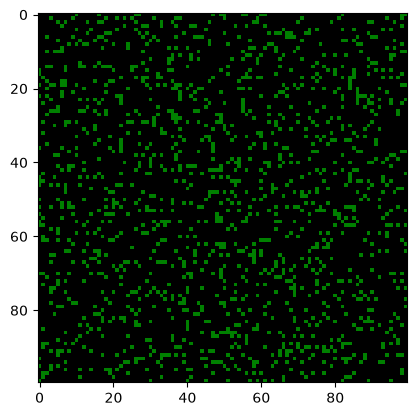

In [161]:
# Run + plot

L = model_step(L, n, p, f, rng)
plot_lattice(L)